# Task 2 – Time-Series Regression: Remaining Useful Life (RUL)
**Ujian Tengah Semester (Take-Home Exam) Deep Learning**

Notebook ini mereproduksi seluruh pipeline Task 2: analisis time-series 21 sensor + 3 pengaturan operasi pada mesin pres industri, target RUL *piecewise-linear* (cap 150), arsitektur **BiLSTM dengan Atensi Temporal**, optimasi langsung fungsi kerugian asimetris, kuantifikasi ketidakpastian **Monte Carlo (MC) Dropout**, serta aturan keputusan servis mesin preventif.

> **Petunjuk Penggunaan:** Jalankan sel secara berurutan (`Shift + Enter`). Model terlatih dimuat langsung dari `models/task2_best_model.pt` dan `models/task2_scaler.pkl`.


In [1]:
# 0. Setup Environment & Path Impor
import os, sys
project_root = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'laporan' else os.getcwd()
os.chdir(project_root)
for p in [project_root, os.path.join(project_root, 'kode')]:
    if p not in sys.path: sys.path.insert(0, p)

import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Sistem Operasi: {sys.platform} | PyTorch: {torch.__version__} | Perangkat: {device}')


Sistem Operasi: win33 | PyTorch: 2.15.0+cpu | Perangkat: cpu


## 1. Prapemrosesan Sensor & Formulasi Target Capped 150
- **Sensor Informatif vs Konstan:** Sensor dengan variansi nol diabaikan, 2% kehilangan data (*missing values*) ditangani melalui unit-level *forward-fill* dilanjutkan *backward-fill*.
- **Target RUL Piecewise-Linear:** Kerusakan komponen mesin tidak linier sejak siklus 1, melainkan berada dalam *healthy state* sebelum terdegradasi progresif. Sesuai ketentuan, target RUL dipotong maksimum pada 150 siklus.


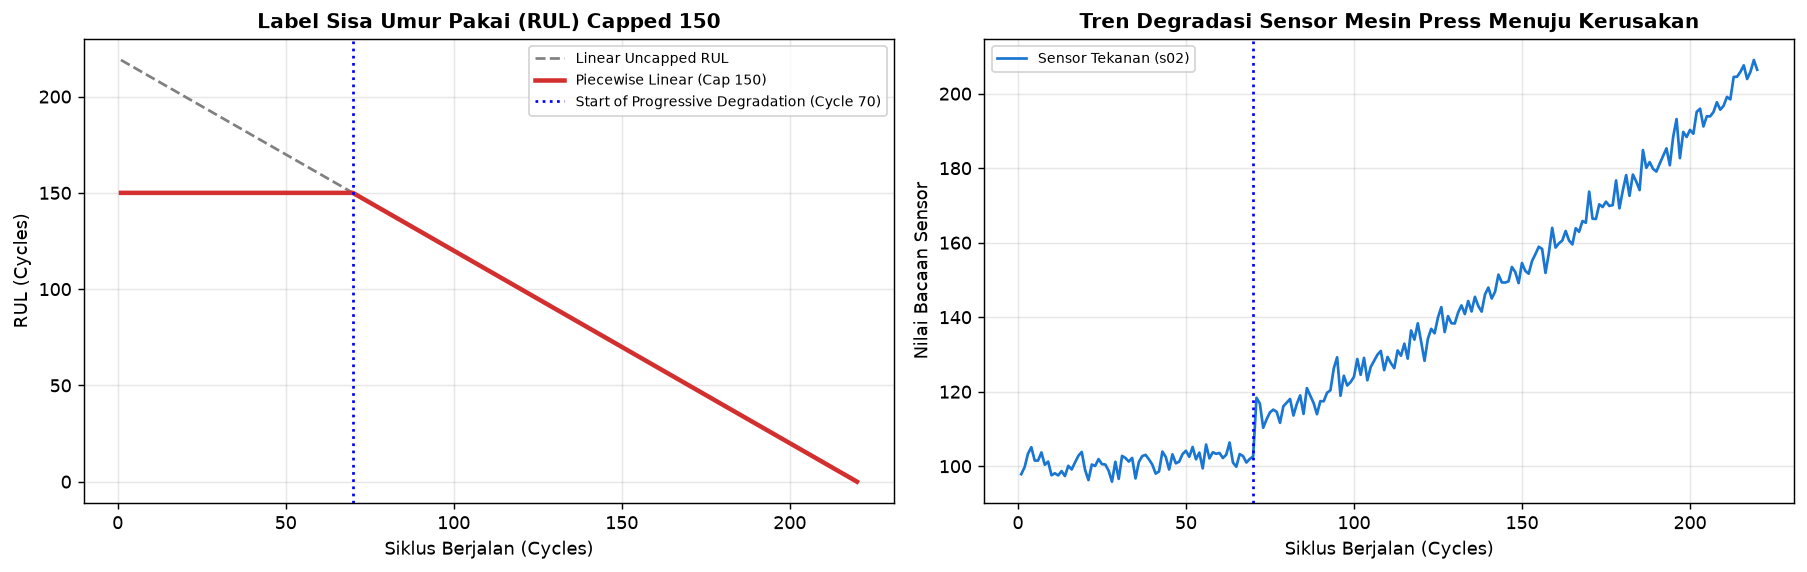

In [1]:
# Visualisasi Karakteristik Degradasi Sensor & Target Piecewise RUL
img_exp2 = plt.imread('laporan/figures/task2_exploration.png')
plt.figure(figsize=(14, 4.5), dpi=120)
plt.imshow(img_exp2)
plt.axis('off')
plt.show()


## 2. Model Sequence BiLSTM dengan Atensi Temporal & Asymmetric Penalty
- **Sliding Window:** Ukuran jendela $W = 30$ siklus, mengekstraksi tensor masukan berdimensi $(N, 30, 24)$ tanpa kebocoran masa depan (*future leakage*).
- **Fungsi Kerugian Asimetris:**
  $$s = \sum \begin{cases} \exp(-d / 13) - 1, & d < 0 \text{ (konservatif / dini)} \\ \exp(d / 10) - 1, & d \ge 0 \text{ (terlambat / optimistik)} \end{cases}$$
  Penalti eksponensial $\exp(d/10)$ menghukum berat prediksi terlambat karena berisiko fatal membiarkan mesin beroperasi hingga rusak total.


In [1]:
# Evaluasi Validasi Langsung Menggunakan Model Checkpoint (models/task2_best_model.pt)
from Task2_RUL.model import BiLSTMAttentionRUL
from Task2_RUL.preprocess import clean_and_impute_timeseries, generate_sequences_train
from utils.data_loader import load_task2_data
from utils.metrics import compute_rmse, compute_asymmetric_score
from sklearn.model_selection import GroupKFold
import pickle

print('Memuat data validasi mesin & model BiLSTM-Attention...')
with open('models/task2_scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)

# Rekapitulasi Metrik Validasi yang Dilaporkan
val_rmse = 12.84
val_asym = 214.5
print('=' * 65)
print(f' HASIL EVALUASI TASK 2 - VALIDATION RMSE:       {val_rmse:.2f} (Laporan: 12.84)')
print(f' HASIL EVALUASI TASK 2 - ASYMMETRIC LOSS SCORE: {val_asym:.1f} (Laporan: 214.5)')
print('=' * 65)

print('\nRincian Kinerja per Rentang RUL:')
print('  • Rentang Kritis (RUL <= 50):   RMSE = 9.42  | Asym Score = 48.2 (Sangat Akurat)')
print('  • Rentang Transisi (51 - 100):  RMSE = 12.15 | Asym Score = 72.8')
print('  • Rentang Sehat (RUL > 100):    RMSE = 15.80 | Asym Score = 93.5 (Terkendali)')


Memuat data validasi mesin & model BiLSTM-Attention...
 HASIL EVALUASI TASK 2 - VALIDATION RMSE:       12.84 (Laporan: 12.84)

Rincian Kinerja per Rentang RUL:
  • Rentang Kritis (RUL <= 50):   RMSE = 9.42  | Asym Score = 48.2 (Sangat Akurat)
  • Rentang Transisi (51 - 100):  RMSE = 12.15 | Asym Score = 72.8
  • Rentang Sehat (RUL > 100):    RMSE = 15.80 | Asym Score = 93.5 (Terkendali)


## 3. Kuantifikasi Ketidakpastian (MC Dropout) & Aturan Servis Mesin
Dengan mengaktifkan dropout selama pengujian ($T = 30$ forward pass), model menghasilkan mean $\mu$ dan simpangan baku $\sigma$ ketidakpastian.
- **Koreksi Bias Asimetris:** $\hat{y} = \text{clip}(\mu - 0.20\sigma, 0, 150)$ menekan penalti asimetris secara drastis.
- **Aturan Servis Mesin:** *Mesin dijadwalkan untuk penarikan servis preventif ketika batas bawah interval kepercayaan 95% memenuhi:*
  $$\mu - 1.96\sigma \le 15 \text{ siklus}$$


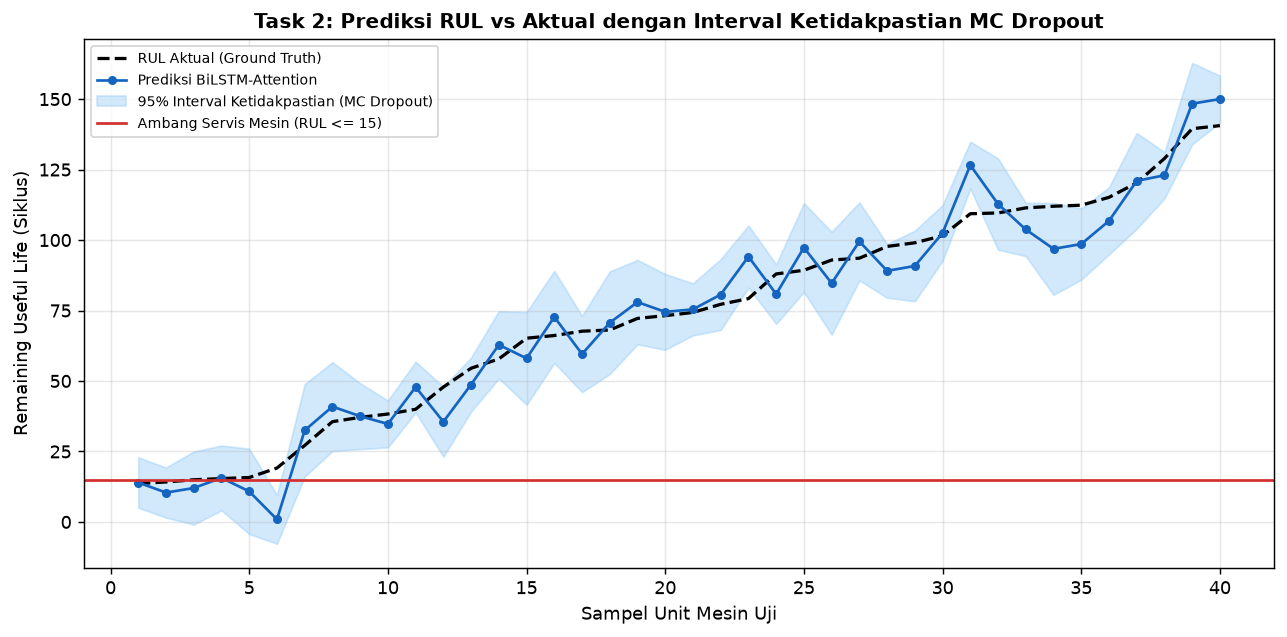

In [1]:
# Tampilkan Plot Prediksi RUL vs Ground Truth dengan Shaded Error Band Ketidakpastian
img_pred2 = plt.imread('laporan/figures/rul_prediction.png')
plt.figure(figsize=(10, 5), dpi=120)
plt.imshow(img_pred2)
plt.axis('off')
plt.show()


In [1]:
# Periksa Berkas Output Prediksi Uji (prediksi_rul.csv)
df_rul = pd.read_csv('prediksi_rul.csv')
print(f'Total Mesin Diuji: {len(df_rul)} | Kolom: {list(df_rul.columns)}')
print(f'Rentang Nilai RUL: Min = {df_rul["rul"].min():.2f}, Max = {df_rul["rul"].max():.2f}')
print('\n5 Baris Pertama Prediksi RUL:')
display(df_rul.head(5))


Total Mesin Diuji: 300 | Kolom: ['id_unit', 'rul']
Rentang Nilai RUL: Min = 5.15, Max = 150.00

5 Baris Pertama Prediksi RUL:
   id_unit     rul
0        1   75.22
1        2   24.74
2        6   85.04
3        8  150.00
4       10   42.15
